# Il problema dei minimi quadrati nell'approssimazione dei dati. I modelli predittivi

Vediamo ora una applicazione del problema dei minimi quadrati alla regressione lineare polinomiale.

Supponiamo di avere un insieme di dati del tipo:

$$
\mathcal{D}=\{(x_i,y_i)\}_{i=1}^{n},
$$

- Le variabili **indipendenti**, o variabili di **input**, che rappresentano un valore noto. Queste sono spesso indicate con il simbolo $x$.
- Le variabili **dipendenti**, o variabili di **output**, che rappresentano il valore che vogliamo prevedere. Queste sono spesso indicate con il simbolo $y$.

> Un **set di dati** è quindi una collezione di coppie di valori $\{ (x_1, y_1), (x_2, y_2), \dots, (x_n, y_n) \}$, tra loro associati.

Come già accennato, gli algoritmi di approssimazione si basano su due assunzioni principali:

1. I dati seguono l'andamento di una **curva** relativamente complessa, ma con un pattern chiaramente riconoscibile.
2. I dati **NON** sono disposti in maniera precisa lungo la curva, ma mostrano un comportamento casuale: sono affetti da *rumore*.

Matematicamente, possiamo rappresentare la prima assunzione dicendo:

> Esiste una funzione $f(x)$ tale per cui $y \approx f(x)$, dove l'errore tra la previsione $f(x)$ e i veri dati $y$ misurati è dovuta al solo rumore.


La seconda ipotesi, invece, si riformula come:

> Esiste una variabile casuale $e$ tale che $y = f(x) + e$ per ogni $x$.

```{note}
Nel seguito, assumeremo sempre che la variabile casuale $e$ abbia distribuzione normale. In particolare, se $y$ rappresenta un vettore di dimensione `(n,)`, allora assumeremo che $e$ sia generata da una funzione del tipo: `np.random.randn(n)`.
```

Date le due assunzioni precedenti, un *metodo di approssimazione* è un qualunque algoritmo che, fissato un modello $f_\theta(x)$ dipendente da un'insieme di parametri $\theta$, calcola il valore dei parametri $\theta$ tali che $f_\theta(x)$ sia il più possibile vicina a $f(x)$.



*Esempio: spesa pubblicitaria e vendite*

Consideriamo un piccolo dataset in cui $x$ rappresenta la spesa pubblicitaria e $y$ le vendite. Cerchiamo una funzione che descriva  la relazione media tra le due variabili per potere prevedere la vendita in corrispondenza di una spesa pubblicitaria non misurata, per esempio $x^*$=9.


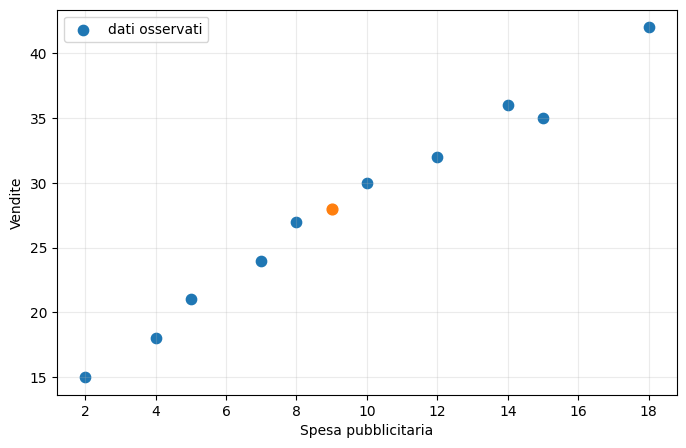

In [37]:
import numpy as np
import matplotlib.pyplot as plt

pubblicita = np.array([2, 4, 5, 7, 8, 10, 12, 14, 15, 18.])
vendite = np.array([15, 18, 21, 24, 27, 30, 32, 36, 35, 42.])
A_reg = np.column_stack((np.ones(len(pubblicita)), pubblicita))
theta, _, _, _ = np.linalg.lstsq(A_reg, vendite, rcond=None)
vendite_stimate = A_reg @ theta

griglia = np.linspace(pubblicita.min(), pubblicita.max(), 200)
retta = theta[0] + theta[1]*griglia

plt.figure(figsize=(8, 5))
plt.scatter(pubblicita, vendite, s=55, label='dati osservati')
plt.scatter(9,28,s=60)
plt.xlabel('Spesa pubblicitaria')
plt.ylabel('Vendite')
plt.legend()
plt.grid(alpha=0.25)
plt.show()


**La scelta del modello**

Gli stessi dati possono essere rappresentati utilizzando famiglie di funzioni differenti. Per esempio, possiamo scegliere come modello una retta oppure una parabola.

![](immagini_sorgente/modelli_lineare_quadratico.png)

<!-- ```{figure} immagini_sorgente/modelli_lineare_quadratico.png
---
width: 100%
align: center
---
```
<p align="center">
  <img src="immagini_sorgente/modelli_lineare_quadratico.png" width="700">
</p> -->

Nel primo caso il modello ha la forma

$$
f(x;\boldsymbol{\theta})=\theta_0+\theta_1x,
$$

mentre nel secondo caso ha la forma

$$
f(x;\boldsymbol{\theta})=\theta_0+\theta_1x+\theta_2x^2.
$$

La famiglia scelta non deve necessariamente essere quella dei polinomi. Per esempio, possiamo considerare una combinazione lineare di una funzione esponenziale e di una costante:

$$
f(x;\boldsymbol{\theta})=\theta_0+\theta_1 e^{\alpha x}.
$$

![](immagini_sorgente/modello_esponenziale.png)

<!-- ```{figure} immagini_sorgente/modello_esponenziale.png
---
width: 100%
align: center
---
```
<p align="center">
  <img src="immagini_sorgente/modello_esponenziale.png" width="700">
</p> -->

La scelta della famiglia di funzioni dipende dal fenomeno che vogliamo descrivere e dalle informazioni disponibili sui dati.

###  Famiglie parametriche di funzioni

Scelta una famiglia di funzioni $f(x;\boldsymbol{\theta})$, occorre determinare i parametri

$$
\boldsymbol{\theta}=(\theta_0,\theta_1,\ldots,\theta_{k-1})^T\in\mathbb{R}^{k}
$$

che identificano la particolare funzione della famiglia che meglio rappresenta i dati.

Per esempio, scegliendo come famiglia le rette del piano, dobbiamo determinare

$$
\boldsymbol{\theta}=(\theta_0,\theta_1)^T,
$$

dove $\theta_0$ è l'intercetta e $\theta_1$ è il coefficiente angolare. Il problema consiste quindi nel trovare la retta che meglio approssima i punti dati.

**Come confrontare due modelli?**

Per stabilire se una funzione rappresenta i dati meglio di un'altra dobbiamo introdurre una misura di vicinanza tra i valori previsti e quelli osservati.

Questo viene fatto definendo una **funzione di costo**, detta anche **funzione di perdita** o *loss function*. Indicata con $h$ la perdita relativa a una singola osservazione, definiamo

$$
\mathcal{L}(\boldsymbol{\theta})
=\sum_{i=1}^{n}h\bigl(f(x_i;\boldsymbol{\theta}),y_i\bigr).
$$

La funzione di costo dipende dai parametri perché, al variare di $\boldsymbol{\theta}$, cambiano le previsioni del modello.

###  Il calcolo dei parametri come problema di minimo

I parametri ottimali sono quelli che rendono minima la funzione di costo:

$$
\boldsymbol{\theta}^{*}
=\operatorname*{argmin}_{\boldsymbol{\theta}\in\mathbb{R}^{k}}
\mathcal{L}(\boldsymbol{\theta}).
$$

La funzione $f(x;\boldsymbol{\theta}^{*})$, i cui parametri sono stati stimati minimizzando la funzione di perdita, prende il nome di **funzione di regressione**.

> Il problema di costruire un modello predittivo viene così trasformato in un problema di minimizzazione.

 **Regressione e perdita quadratica**

Nella regressione si utilizza frequentemente la perdita quadratica

$$
h\bigl(f(x_i;\boldsymbol{\theta}),y_i\bigr)
=\bigl(f(x_i;\boldsymbol{\theta})-y_i\bigr)^2.
$$

La funzione di costo diventa quindi

$$
\mathcal{L}(\boldsymbol{\theta})
=\sum_{i=1}^{n}\bigl(f(x_i;\boldsymbol{\theta})-y_i\bigr)^2.
$$

Ogni termine misura il quadrato del residuo relativo all'osservazione $i$. Gli errori di segno opposto non si cancellano e gli errori grandi vengono penalizzati maggiormente.



Nel caso della **regressione lineare**, il polinomio è una retta:

$$
f(x;\boldsymbol{\theta})=\theta_0+\theta_1x.
$$

Nel caso della **regressione quadratica**, il polinomio è una parabola:

$$
f(x;\boldsymbol{\theta})=\theta_0+\theta_1x+\theta_2x^2.
$$

In generale, un polinomio di grado $k$ dipende da $k+1$ parametri:

$$
f(x;\boldsymbol{\theta})
=\theta_0+\theta_1x+\theta_2x^2+\cdots+\theta_kx^k.
$$

*La funzione di perdita per la regressione polinomiale*

Sostituendo il modello polinomiale nella perdita quadratica otteniamo

$$
\mathcal{L}(\boldsymbol{\theta})
=\sum_{i=1}^{n}
\left(\theta_0+\theta_1x_i+\theta_2x_i^2+\cdots+\theta_kx_i^k-y_i\right)^2.
$$

Introduciamo i vettori

$$
\boldsymbol{\theta}=(\theta_0,\theta_1,\ldots,\theta_k)^T,
\qquad
\mathbf{y}=(y_1,y_2,\ldots,y_n)^T,
$$

e la matrice

$$
\Phi=
\begin{pmatrix}
x_1^0 & x_1^1 & \cdots & x_1^k\\
x_2^0 & x_2^1 & \cdots & x_2^k\\
\vdots & \vdots & \ddots & \vdots\\
x_n^0 & x_n^1 & \cdots & x_n^k
\end{pmatrix}
\in\mathbb{R}^{n\times(k+1)}.
$$

La matrice $\Phi$ viene spesso chiamata **matrice del modello** o **design matrix**.

*Formulazione matriciale*

Il vettore delle previsioni del modello sui punti osservati è

$$
\widehat{\mathbf{y}}=\Phi\boldsymbol{\theta}.
$$

Il vettore dei residui è quindi

$$
\mathbf{r}=\Phi\boldsymbol{\theta}-\mathbf{y},
$$

e la funzione di perdita può essere scritta in forma compatta come

$$
\mathcal{L}(\boldsymbol{\theta})
=\|\Phi\boldsymbol{\theta}-\mathbf{y}\|_2^2.
$$



La determinazione dei coefficienti del polinomio conduce quindi al problema dei minimi quadrati lineari.

$$
\min_{\boldsymbol{\theta}\in\mathbb{R}^{k+1}}
\|\Phi\boldsymbol{\theta}-\mathbf{y}\|_2^2,
$$



*Il problema*

Supponiamo di osservare coppie $(x_i,y_i)$ e di voler descrivere la relazione con una retta

$$
y_i\approx\theta_0+\theta_1x_i.
$$

Per tutte le osservazioni il modello diventa

$$
\underbrace{\begin{bmatrix}
1&x_1\\1&x_2\\\vdots&\vdots\\1&x_m
\end{bmatrix}}_{A}
\underbrace{\begin{bmatrix}\theta_0\\\theta_1\end{bmatrix}}_{x}
\approx
\underbrace{\begin{bmatrix}y_1\\y_2\\\vdots\\y_m\end{bmatrix}}_{b}.
$$

La prima colonna di uno permette di rappresentare l'intercetta $\theta_0$. Stimare la retta significa risolvere un problema lineare ai minimi quadrati.



<!-- ```{figure} immagini_sorgente/fig_regressione_residui.png
---
width: 100%
align: center
---
```

<p align="center">
  <img src="immagini_sorgente/fig_regressione_residui.png" width="700">
</p> -->

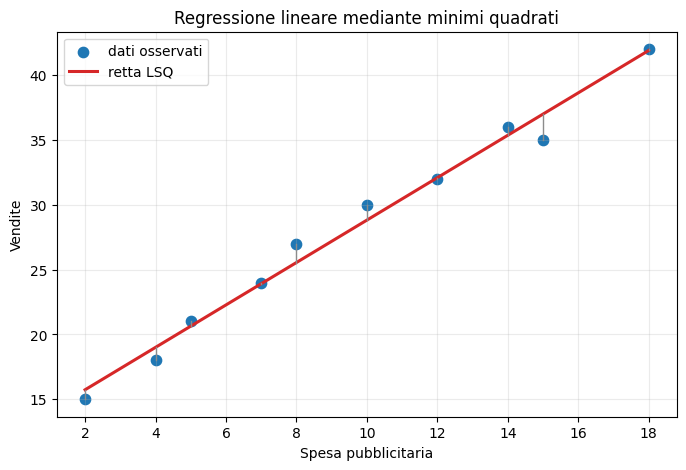

Intercetta  = 12.458
Pendenza   = 1.636


In [38]:
import numpy as np
import matplotlib.pyplot as plt

pubblicita = np.array([2, 4, 5, 7, 8, 10, 12, 14, 15, 18.])
vendite = np.array([15, 18, 21, 24, 27, 30, 32, 36, 35, 42.])
A_reg = np.column_stack((np.ones(len(pubblicita)), pubblicita))
theta, _, _, _ = np.linalg.lstsq(A_reg, vendite, rcond=None)
vendite_stimate = A_reg @ theta

griglia = np.linspace(pubblicita.min(), pubblicita.max(), 200)
retta = theta[0] + theta[1]*griglia

plt.figure(figsize=(8, 5))
plt.scatter(pubblicita, vendite, s=55, label='dati osservati')
plt.plot(griglia, retta, color='tab:red', lw=2.2, label='retta LSQ')
for x_i, y_i, yh_i in zip(pubblicita, vendite, vendite_stimate):
    plt.plot([x_i, x_i], [yh_i, y_i], color='0.55', lw=1)
plt.xlabel('Spesa pubblicitaria')
plt.ylabel('Vendite')
plt.title('Regressione lineare mediante minimi quadrati')
plt.legend()
plt.grid(alpha=0.25)
plt.show()

print(f'Intercetta  = {theta[0]:.3f}')
print(f'Pendenza   = {theta[1]:.3f}')

*Interpretazione dei coefficienti*

Nel modello

$$
\widehat y=\theta_0+\theta_1t,
$$

l'intercetta $\theta_0$ è il valore previsto quando $t=0$, mentre la pendenza $\theta_1$ è la variazione media prevista di $y$ associata a un aumento unitario di $t$.

Questa interpretazione deve essere fatta nel dominio osservato: estrapolare molto oltre i valori presenti nei dati può essere inaffidabile. Inoltre una relazione statistica non implica automaticamente un rapporto causale.

### Misure dell'errore: che cosa ci dicono?

Una volta calcolata la retta, vogliamo capire **quanto le sue previsioni si avvicinano ai valori osservati**. Indichiamo con:

- $m$ il numero di osservazioni;
- $y_i$ il valore osservato per il dato $i$;
- $\widehat y_i$ il valore previsto dal modello per lo stesso dato;
- $\overline y=\frac{1}{m}\sum_{i=1}^{m}y_i$ la media dei valori osservati.

Il **residuo** è

$$
e_i=y_i-\widehat y_i.
$$

Nel grafico è lo scarto verticale, con segno, tra il punto osservato e la retta. Se $e_i>0$, il modello **sottostima** il valore osservato; se $e_i<0$, lo **sovrastima**; se $e_i=0$, la previsione coincide con il dato.

Per esempio, se le vendite osservate sono $30$ e quelle previste sono $28$, il residuo è $2$. Se il modello prevede $32$, il residuo è $-2$. Sommando semplicemente i residui, questi due errori si cancellerebbero: per misurare l'errore complessivo usiamo quindi i loro quadrati.

Il residuo è uno scarto rispetto al dato osservato, che può contenere rumore: non coincide necessariamente con l'errore rispetto a un valore vero non conosciuto.

#### SSE: somma dei quadrati dei residui

$$
\mathrm{SSE}=\sum_{i=1}^{m}e_i^2
=\sum_{i=1}^{m}(y_i-\widehat y_i)^2.
$$

La SSE (*sum of squared errors*), chiamata anche RSS (*residual sum of squares*), misura lo **scostamento quadratico complessivo** tra dati e previsioni. È proprio la quantità che minimizziamo nel problema dei minimi quadrati.

Ogni osservazione contribuisce con $e_i^2$: un residuo di ampiezza $4$ pesa quattro volte più di un residuo di ampiezza $2$, perché $4^2=16$ e $2^2=4$. Gli scarti grandi sono quindi penalizzati maggiormente.

La SSE è sempre non negativa ed è zero solo se tutte le previsioni coincidono con i dati. A parità di dati, una SSE più piccola indica un migliore adattamento. Essendo una somma, dipende anche dal numero di osservazioni: non è adatta a confrontare direttamente insiemi di dimensioni diverse. Se $y$ è misurata in euro, la SSE è misurata in euro al quadrato.

#### MSE e RMSE: dall'errore complessivo a una misura per osservazione

L'**errore quadratico medio** è

$$
\mathrm{MSE}=\frac{1}{m}\sum_{i=1}^{m}e_i^2
=\frac{\mathrm{SSE}}{m}.
$$

La MSE (*mean squared error*) divide la SSE per il numero di dati e rappresenta quindi il **quadrato del residuo mediato sulle osservazioni**. Per confrontare i valori ottenuti su insiemi diversi occorre comunque considerare la stessa variabile, nella stessa unità di misura, e popolazioni confrontabili. Per $m$ fissato, minimizzare MSE o SSE produce lo stesso modello.

Poiché anche la MSE ha unità di misura al quadrato, spesso si considera la sua radice:

$$
\mathrm{RMSE}=\sqrt{\mathrm{MSE}}
=\sqrt{\frac{1}{m}\sum_{i=1}^{m}e_i^2}.
$$

La RMSE (*root mean squared error*) ha **la stessa unità di misura di $y$** e dà una misura della dimensione tipica degli scarti, attribuendo maggior peso a quelli grandi. Per esempio, una RMSE di $50$ euro indica una scala degli scarti di $50$ euro secondo questa misura quadratica: non significa che ogni previsione sbagli di $50$ euro, né che lo scarto assoluto medio sia $50$ euro.

SSE, MSE e RMSE sono tutte migliori quando sono **più piccole**. Quanto sia accettabile una certa RMSE dipende dalla scala dei dati e dall'applicazione.


#### Il coefficiente di determinazione $R^2$: confronto con la media

Un errore piccolo in valore assoluto non basta a capire quanto sia utile il modello. Introduciamo allora un riferimento molto semplice: **prevedere sempre la media $\overline y$**, senza usare la spesa pubblicitaria.

L'errore quadratico complessivo di questa previsione costante è

$$
\mathrm{SST}=\sum_{i=1}^{m}(y_i-\overline y)^2.
$$

La SST (*total sum of squares*) misura quanto i valori osservati sono dispersi attorno alla loro media. Confrontiamo l'errore del nostro modello con questo riferimento:

$$
R^2=1-\frac{\mathrm{SSE}}{\mathrm{SST}}
=1-\frac{\sum_{i=1}^{m}(y_i-\widehat y_i)^2}
{\sum_{i=1}^{m}(y_i-\overline y)^2}.
$$

Il rapporto $\mathrm{SSE}/\mathrm{SST}$ è la **quota di errore quadratico rimasta rispetto alla previsione costante basata sulla media**. Sottraendola da $1$ otteniamo la riduzione relativa dell'errore. Per esempio, $R^2=0{,}80$ significa che l'errore quadratico è il $20\%$ di quello del riferimento: il modello lo ha ridotto dell'$80\%$.

| Valore | Significato sui dati valutati |
|:--|:--|
| $R^2=1$ | La SSE è zero: tutte le previsioni coincidono con i valori osservati. |
| $0<R^2<1$ | Il modello ha un errore quadratico inferiore alla previsione costante $\overline y$. |
| $R^2=0$ | Il modello ha lo stesso errore quadratico della previsione costante $\overline y$. Non deve necessariamente produrre le stesse previsioni. |
| $R^2<0$ | Il modello ha un errore quadratico maggiore della previsione costante $\overline y$. |

$R^2$ è **adimensionale** e si preferiscono valori più alti. Se $\mathrm{SST}>0$, non supera $1$, ma può essere negativo e non ha un limite inferiore finito.

Per una regressione ordinaria ai minimi quadrati **con intercetta**, valutata sugli stessi dati usati per stimare i coefficienti, vale $0\le R^2\le1$: la previsione costante è una delle possibilità del modello, quindi il minimo non può essere peggiore di quel riferimento. Su dati nuovi, o in assenza di intercetta, questa garanzia non vale. Se tutti gli $y_i$ sono uguali, $\mathrm{SST}=0$ e la formula di $R^2$ non è definita.

**Un $R^2$ elevato non è una percentuale di previsioni corrette**, non dimostra un rapporto di causa-effetto e non garantisce buone previsioni su nuovi dati. Aggiungendo variabili o aumentando il grado di un polinomio in modelli ai minimi quadrati annidati, $R^2$ sui dati di addestramento non diminuisce, anche se la capacità predittiva può peggiorare. Per questo le metriche vanno calcolate anche su dati non usati per stimare il modello.

Quando si calcola la formula standard di $R^2$ su un test set, $\overline y$ è la media dei valori osservati **nel test set**: serve soltanto come riferimento per la valutazione, non per addestrare il modello.

In [39]:
errori = vendite - vendite_stimate
SSE = np.sum(errori**2)
MSE = SSE / len(vendite)
RMSE = np.sqrt(MSE)

# Errore del riferimento che prevede sempre la media dei valori osservati.
media_vendite = vendite.mean()
SST = np.sum((vendite - media_vendite)**2)
R2 = 1 - SSE / SST if SST > 0 else np.nan

print(f'Media delle vendite = {media_vendite:.4f}')
print(f'SSE  = {SSE:.4f}')
print(f'MSE  = {MSE:.4f}')
print(f'RMSE = {RMSE:.4f}')
print(f'SST  = {SST:.4f}')
print(f'R^2  = {R2:.4f}')


Media delle vendite = 28.0000
SSE  = 9.6033
MSE  = 0.9603
RMSE = 0.9800
SST  = 664.0000
R^2  = 0.9855


#### Interpretazione dei risultati dell'esempio

Per i dieci dati su spesa pubblicitaria e vendite, la media delle vendite è $\overline y=28$. I risultati sono:

$$
\mathrm{SSE}\approx9{,}6033,\qquad
\mathrm{MSE}\approx0{,}9603,\qquad
\mathrm{RMSE}\approx0{,}9800.
$$

La retta produce quindi scarti dell'ordine di **una unità di vendita**, secondo la misura quadratica. La previsione costante $\widehat y_i=28$ avrebbe invece un errore complessivo $\mathrm{SST}=664$. Pertanto

$$
R^2=1-\frac{9{,}6033}{664}\approx0{,}9855.
$$

Questi risultati descrivono l'adattamento sui dati usati per calcolare la retta. Non dimostrano che il 98,55% delle vendite sia causato dalla pubblicità, né che le previsioni future avranno lo stesso errore.

### Overfitting nella regressione polinomiale

Un polinomio che passa per tutti i punti osservati è sempre il modello migliore? **No: può adattarsi anche al rumore e prevedere male i valori in altri punti.**

Costruiamo due esempi con 11 punti del piano. Confrontiamo un modello troppo semplice (*underfitting*), uno che rappresenta bene l'andamento e uno eccessivamente flessibile (*overfitting*).

In entrambi i casi i dati sono generati da

$$y_i=f(x_i)+\varepsilon_i,\qquad \varepsilon_i\sim\mathcal N(0,0.16^2).$$

Il polinomio di grado $d$ è stimato con i minimi quadrati:

$$p_d(x)=\sum_{j=0}^{d}\theta_j x^j,\qquad
\min_{\theta_0,\ldots,\theta_d}\sum_{i=1}^{11}(p_d(x_i)-y_i)^2.$$

Il grado 10 ha 11 coefficienti e, per 11 ascisse distinte, può interpolare tutti i punti (a meno degli errori numerici). Questo non garantisce che descriva bene la funzione che ha generato i dati.

*Esempio 1*

La funzione generatrice è $f(x)=0.5+1.2x^2$. Le ordinate osservate sono perturbate da un piccolo rumore.

- **Grado 1:** una retta non può rappresentare la curvatura della parabola.
- **Grado 2:** il modello ha la forma corretta e segue l'andamento generale senza inseguire ogni perturbazione.
- **Grado 10:** il polinomio passa per tutti gli 11 punti, ma presenta forti oscillazioni tra i punti, soprattutto vicino agli estremi.

La curva tratteggiata mostra la funzione generatrice, nota perché l'esempio è simulato. I punti scuri sono gli stessi in tutti e tre i pannelli.

![Confronto dei gradi 1, 2 e 10 per dati quadratici.](immagini_sorgente/01_parabola.png)

**Che cosa osservare:** l’errore di training del grado 10 è quasi nullo, ma l’errore sui nuovi dati è maggiore di quello del grado 2. Le oscillazioni avvengono dentro l’intervallo osservato: non si tratta di estrapolazione.

*Esempio 2*

Ora la funzione generatrice è $f(x)=\sin(\pi x)$, sempre per $x\in[-1,1]$. La funzione vera non è un polinomio, ma può essere ben approssimata da un polinomio di grado moderato sull'intervallo considerato.

Confrontiamo i gradi **1, 5 e 10**. Il grado 5 segue l'andamento sinusoidale; il grado 10 segue anche le perturbazioni dei singoli dati e produce oscillazioni che non appartengono alla funzione generatrice.

![Confronto dei gradi 1, 5 e 10 per dati sinusoidali.](immagini_sorgente/02_sinusoide.png)

*Errore sui dati osservati ed errore su dati nuovi*

Per ogni grado da 1 a 10, calcoliamo:

$$\operatorname{RMSE}_{\mathrm{train}}=
\sqrt{\frac{1}{11}\sum_{i=1}^{11}(y_i-p_d(x_i))^2},$$

$$\operatorname{RMSE}_{\mathrm{test}}=
\sqrt{\frac{1}{N_{\mathrm{test}}}\sum_{j=1}^{N_{\mathrm{test}}}
(y_j^{\mathrm{test}}-p_d(x_j^{\mathrm{test}}))^2}.$$

I 2000 punti di test sono generati indipendentemente nello stesso intervallo, con lo stesso livello di rumore; non sono usati per stimare i coefficienti. Il test misura quindi l'errore su **nuove osservazioni rumorose**, non soltanto la distanza dalla curva tratteggiata.

Con i minimi quadrati non regolarizzati, aumentando il grado l'errore di training non aumenta: ogni famiglia contiene le precedenti. L'errore di test può invece crescere. È questo peggioramento sui nuovi dati, insieme all'ottimo adattamento ai dati osservati, a evidenziare l'overfitting.

La linea orizzontale $\sigma=0.16$ indica la RMSE teorica della funzione generatrice rispetto a nuove osservazioni, nel limite di molti dati: il rumore nei nuovi dati resta anche se conosciamo $f$.

![RMSE di training e test al crescere del grado, nei due esempi.](immagini_sorgente/03_errori_grado.png)

Esempio.

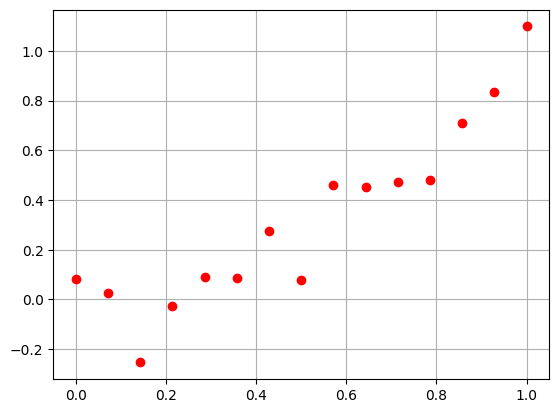

In [40]:
# Numero di dati
n = 15

# Definiamo gli x_i
x = np.linspace(0, 1, n)

#Definizamo gli y_i
y=x*x+np.random.normal(loc=0, scale=0.1, size=(n, ))

plt.plot(x, y, 'ro')
plt.grid()
plt.show()


In [41]:
def vandermonde(x, d):
    r"""
    Preso in input un numpy array "x" di lunghezza (n, ) contentente i dati, e un valore intero "d" rappresentante il grado del polinomio, 
    costruisce e ritorna la matrice di vandermonde X di grado d, associata a x.

    Parameters:
    x (ndarray): Il vettore dei dati di input.
    d (int): Il grado massimo del polinomio.

    Returns:
    X (ndarray): La matrice di Vandermonde di grado "d", associata ad x.
    """
    n = x.shape[0]
    
    # Inizializzo la matrice di Vandermonde con shape (n, d+1)
    X = np.zeros((n, d+1))
    
    # Costruisco la matrice di Vandermonde
    for i in range(d+1):
        X[:, i] = x ** i
    return X

# Definiamo la matrice di Vandermonde tramite la funzione appena definita con grado d = 5
#d = 3 #grado polinomio approssimante 
#X = vandermonde(x, d)


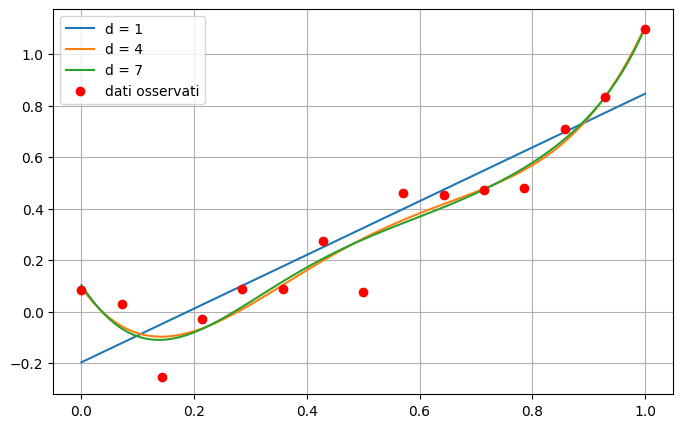

In [42]:

# Definiamo la funzione f(x, alpha) che prende in input il vettore alpha dei coefficienti e un vettore x di lunghezza n, e ritorna il valore del rispettivo polinomio calcolato su x elemento per elemento
def f(x, alpha):
    d = alpha.shape[0] - 1 # abbiamo detto che la shape di alpha è (d+1, )

    y = np.zeros_like(x) # Questa è l'unica riga che dobbiamo cambiare rispetto a prima!
    for i in range(d+1):
        y = y + alpha[i] * x ** i
    return y
xx = np.linspace(0, 1, 100)
theta_star = []
plt.figure(figsize=(8, 5))
for d in range(1, 9, 3):
    X = vandermonde(x, d)
    coefficienti, residui, rango, valori_singolari = np.linalg.lstsq(X, y, rcond=None)
    theta_star.append(coefficienti)  # Aggiungiamo un elemento alla lista.
    # Rappresentiamo la curva approssimata in [0, 1].
    yy_eqn = f(xx, coefficienti)
    plt.plot(xx, yy_eqn, label=f"d = {d}")
plt.plot(x, y, 'ro', label='dati osservati')
plt.legend()
plt.grid()
plt.show()


## Underfit/Overfit
Tra le curve della figura sopra, osserviamo tre comportamenti distinti:

- Se $d=1$, la curva rappresenta una retta, e non è quindi sufficientemente flessibile da riuscire a recuperare il comportamento **complesso** della curva corretta. Il risultato sarà una scarsa approssimazione, incapace di recuperare l'andamento corretto dei dati. Questo fenomeno è spesso noto con il termine **underfit**.
- Se $d=7$, la curva diventa troppo flessibile, e inizia a seguire l'andamento oscillatorio del rumore. Questa curva, seppur in apparenza relativamente corretta, si comporterà non meglio di quella con $d=1$ in termini di abilità predittiva poiché, avendo imparato il comportamento del rumore, non è riuscita ad estrarre in maniera efficace il comportamento corretto della curva, e fallirà inevitabilmente se utilizzata per fare predizioni. Questo fenomento è noto con il nome di **overfit**.
- Se $d=4$, la curva ha un comportamento migliore.

Diventa quindi chiaro come lo scopo finale nella costruzione di una curva di approssimazione sarà quello di identificare il valore corretto per l'iperparametro $d$, così da evitare in maniera efficace sia overfit che underfit.

Evitare situazioni di underfit è relativamente semplice andando a visualizzare il valore del residuo al variare del grado $d$ del polinomio approssimante:

In [43]:
def residuo(X, y, alpha):
    # Somma dei quadrati dei residui (SSE).
    r = np.linalg.norm(X @ alpha - y) ** 2
    return r

theta_star = []
for d in range(6):
    # Matrice e coefficienti devono riferirsi allo stesso grado d.
    X = vandermonde(x, d)
    coefficienti, _, _, _ = np.linalg.lstsq(X, y, rcond=None)
    theta_star.append(coefficienti)
    print(f"Residuo per d = {d}: {residuo(X, y, theta_star[d]):.6f}.")


Residuo per d = 0: 1.868137.
Residuo per d = 1: 0.313654.
Residuo per d = 2: 0.165849.
Residuo per d = 3: 0.164708.
Residuo per d = 4: 0.107773.
Residuo per d = 5: 0.106944.


Osserviamo come il valore del residuo è molto grande quando $d$ è troppo piccolo, per poi scendere rapidamente quando ci si avvicina al valore esatto. 

```{note}
L'**underfit** rappresenta una curva di approssimazione poco flessibile. E' quindi estremamente semplice riconoscerlo andando a stampare il valore del residuo per ogni determinata scelta dell'iperparametro.
```

Non è altrettando semplice identificare l'overfit, poiché come si vede il residuo per $d=5$ è addirittura inferiore al residuo per $d=3$. Questo comportamento deriva dal fatto che il modello in overfit ha iniziato ad interpolare il rumore, e questo comporta una riduzione *fittizia* del residuo, che non correla però con una maggior abilità di far previsione.

Identificare l'overfit in maniera automatica è infatti uno dei grandi problemi aperti di questo campo al giorno d'oggi, poiché gli algoritmi ad oggi noti richiedono delle assunzioni che portano spesso ad una riduzione generale delle performance. 

Nella prossima sezione, vediamo un metodo semplice ma efficace per attenuare (e sperabilmente risolvere) il problema dell'overfit, una volta che lo si è individuato.

## Regolarizzazione
L'idea di questo approccio è la seguente: supponiamo che $d=3$ sia il grado **ottimale** per l'approssimazione, ma noi scegliamo (scorrettamente) $d=5$. Se gli ultimi due valori di $\alpha$ sono uguali a zero, allora il risultato ottenuto sarà come se avessimo scelto $d=3$.

Chiaramente, non possiamo sapere a priori esattamente quanti parametri dovranno essere uguali a zero. Ci limitiamo quindi a richiedere la nostro modello di porre *il maggior numero possibile* di valori uguale a zero, riducendo al minimo l'impatto sull'approssimazione.

Questo si riduce ad una formulazione del tipo seguente:

$$
\min_{\alpha} \frac{1}{2}|| X\alpha - y ||_2^2 + \frac{\lambda}{2} || \alpha ||_2^2,
$$

dove il primo termine è il classico problema ai minimi quadrati che abbiamo già visto precedentemente, mentre il secondo serve a richiedere che i valori di $\alpha$ siano il più piccoli possibile, andando quindi a forzare la presenza di vari elementi uguali a $0$, come detto. Questo termine è spesso chiamato **termine di regolarizzazione** e, se viene scelto nella forma appena descritto, prende il nome di **termine di regolarizzazione alla Tikhonov**.

Per risolvere questo problema di minimo, osserviamo che il suo gradiente è uguale a $0$ (e siamo quindi in presenza di un minimo), se:

$$
X^T X \alpha - X^T y + \lambda \alpha = 0,
$$

e quindi se

$$
(X^T X + \lambda I) \alpha = X^T y.
$$

Da notare che il sistema appena descritto rappresenta un'estensione naturale delle equazioni normali già utilizzate per i problemi dei minimi quadrati. Infatti, ponendo $\alpha = 0$, si ottengono esattamente le equazioni normali.

Notare che questo sistema può essere risolto anch'esso sia mediante fattorizzazione LU, sia tramite Decomposizione ai Valori Singolari. Vediamo come risolverla tramite equazioni normali con fattorizzazione LU.

In [44]:
# Grado del polinomio e matrice del modello.
d = 5
X = vandermonde(x, d)

# Il nome "lambda" è riservato nel linguaggio Python.
lmbda = 1

# Equazioni normali regolarizzate: A = X^T X + lambda * I.
A = X.T @ X + lmbda * np.eye(d + 1)
alpha_tik = np.linalg.solve(A, X.T @ y)


Vediamo come si comporta la curva di approssimazione con $d=5$ vista sopra, al variare del parametro $\lambda$.

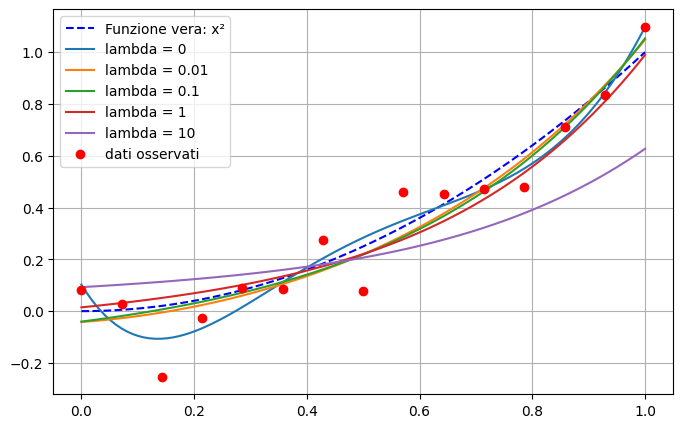

In [45]:
# Calcoliamo le soluzioni con lambda variabile e salviamole in una lista.
lmbda_list = [0, 1e-2, 1e-1, 1, 10]

d = 5
X = vandermonde(x, d)

alpha_tik = []
for lmbda in lmbda_list:
    # La matrice cambia a ogni valore del parametro di regolarizzazione.
    A = X.T @ X + lmbda * np.eye(d + 1)
    if lmbda == 0:
        # Caso non regolarizzato: risoluzione diretta ai minimi quadrati.
        coefficienti, _, _, _ = np.linalg.lstsq(X, y, rcond=None)
    else:
        coefficienti = np.linalg.solve(A, X.T @ y)
    alpha_tik.append(coefficienti)

# La funzione generatrice dei dati di questo esempio è y = x^2.
alpha_true = np.array([0., 0., 1.])
xx = np.linspace(0, 1, 100)
yy_true = f(xx, alpha_true)

plt.figure(figsize=(8, 5))
plt.plot(xx, yy_true, 'b--', label='Funzione vera: x²')
for lmbda, coefficienti in zip(lmbda_list, alpha_tik):
    yy_tik = f(xx, coefficienti)
    plt.plot(xx, yy_tik, label=f"lambda = {lmbda}")
plt.plot(x, y, 'ro', label='dati osservati')
plt.legend()
plt.grid()
plt.show()


E' dunque abbastanza palese come, per valori relativamente piccoli di $\lambda$, la soluzione ottenuta è molto migliore di quella che avevamo visto nel caso precedente in cui non era presente il termine di regolarizzazione, e come questo metodo permette di ottenere un buon modello approssimante anche senza stimare in maniera precisa il grado *corretto* del polinomio.

Chiaramente, nel caso in cui $\lambda$ sia scelto troppo grande, il termine di Regolarizzazione inizia a dominare in maniera esagerata la soluzione, generando una curva che manifesta dei parametri **troppo piccoli**, e che quindi non è in grado di fittare correttamente i dati considerati, portando a **underfit**.

Nonostante ciò, scegliere un parametro $\lambda$ adeguato è in pratica **estremamente** più semplice di trovare il grado corretto, sia perché sono presenti in letteratura vari metodi per selezionarlo automaticamente, sia perché come si vede dall'esempio sopra il range di valori di $\lambda$ per cui la ricostruzione è buona è particolarmente grande.

*Addestramento e valutazione predittiva*

Un errore piccolo sui dati usati per stimare i coefficienti non garantisce buone previsioni su nuovi dati. In un'applicazione predittiva bisogna:

1. separare i dati in training set e test set;
2. stimare i coefficienti usando soltanto il training set;
3. applicare il modello al test set;
4. calcolare RMSE o altre metriche sui dati non utilizzati nell'addestramento.

Questa distinzione riguarda la capacità di generalizzazione del modello, non soltanto la soluzione numerica del problema LSQ.